In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import *
from plotnine import *
import scanpy as sc
import anndata as ad
from matplotlib.path import Path
import os
from scib.metrics import *
from sklearn.neighbors import NearestNeighbors
from pathlib import Path



/nfs/home/students/s.reif/miniforge3/envs/sdd-metrics-real/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_csv from `anndata` is deprecated. Import anndata.io.read_csv instead.
/nfs/home/students/s.reif/miniforge3/envs/sdd-metrics-real/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_excel from `anndata` is deprecated. Import anndata.io.read_excel instead.
/nfs/home/students/s.reif/miniforge3/envs/sdd-metrics-real/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_hdf from `anndata` is deprecated. Import anndata.io.read_hdf instead.
/nfs/home/students/s.reif/miniforge3/envs/sdd-metrics-real/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_loom from `anndata` is deprecated. Import anndata.io.read_loom instead.
/nfs/home/students/s.reif/miniforge3/envs/sdd-metrics-real/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_mtx from `annd

In [ ]:
# reading in csvs from each directory and converting to 1D arrays

def load_csvs_to_arrays(data_path, dirs):
        dict_all_methods = {}

        for csv_file in dirs:
            array_name = os.path.splitext(csv_file)[0]
            array_name_df = pd.read_csv(os.path.join(data_path, csv_file), header=None)
            globals()[array_name] = array_name_df.to_numpy().flatten()
            # adata.obs[array_name] = globals()[array_name]
            print(f"Loaded {array_name} from {csv_file}")
            if array_name != "groundtruth":
                dict_all_methods[array_name] = globals()[array_name]
            else:
                groundtruth = globals()[array_name]
            
            return dict_all_methods, groundtruth
            
        print(f"Total arrays loaded: {len(dict_all_methods)}")
        print("Arrays:", [os.path.splitext(csv_file)[0] for csv_file in dirs])
        print(dict_all_methods)



In [7]:
# read in all csv files from datapath into 1D arrays

# read in each dir seperately if there are multiple dirs in the path directory: includingmultipel datasets (and anndatas)

data_path = "/nfs/home/students/s.reif/SysMed/SysBioSDD/evaluation_metrics/examples_csvs/"

for dir in os.listdir(data_path):
    print(f"Directory found: {dir}")
    
    data_path_dir = f"{data_path}{dir}"
    dirs = os.listdir(data_path_dir)
    dict_all_methods, groundtruth = load_csvs_to_arrays(data_path_dir, dirs)
    # adata as file in path that ends with .h5ad
    for file in os.listdir(data_path_dir):
        if file.endswith(".h5ad"):
            h5ad_file = os.path.join(data_path_dir, file)
            print(f"Loading AnnData from {h5ad_file}")
            adata = sc.read_h5ad(h5ad_file)
            break
    else:
        print("No .h5ad file found in the directory.")

Directory found: example
Loaded ensemble from ensemble.csv


ValueError: not enough values to unpack (expected 2, got 1)

In [ ]:
dict_all_methods, groundtruth = load_csvs_to_arrays(data_path_dir, dirs)


# General Visualizations: UMAP and sankey plots

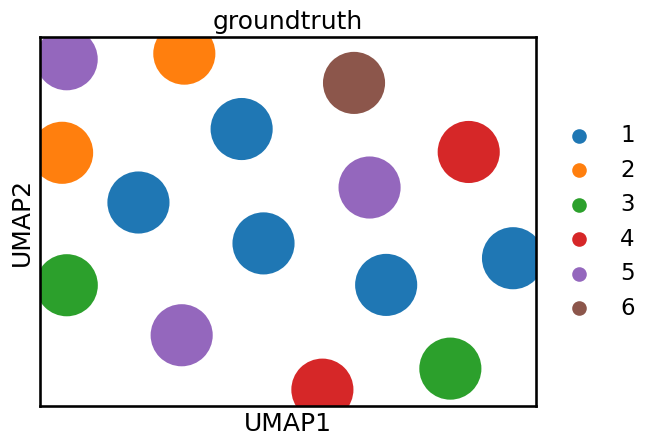

In [ ]:
# general UMAP visualizations for all arrays

# Dummy data for UMAP
#adata = ad.AnnData(X=np.random.rand(len(groundtruth), 10)) 

# path for umap plots
umap_path = "/nfs/home/students/s.reif/SysMed/SysBioSDD/evaluation_metrics/plots"

def umap_plot(adata, dict_methods, umap_path, groundtruth=None,):
    
    sc.settings.figdir = Path(umap_path)

    if not os.path.exists(umap_path):
        os.makedirs(umap_path)

    if groundtruth is not None:
            adata.obs['groundtruth'] = pd.Categorical(groundtruth)
            sc.pp.neighbors(adata)
            sc.tl.umap(adata)
            sc.pl.umap(adata, color='groundtruth', title='groundtruth', save = "_groundtruth.png")
            # save umap plot
            #plt.savefig(os.path.join(umap_path, "umap_groundtruth.png"))
            #plt.close() 
            
    for method_name, values in dict_all_methods.items():
        adata.obs[method_name] = pd.Categorical(values)
        if 'X_umap' not in adata.obsm:
            sc.pp.neighbors(adata)
            sc.tl.umap(adata)
        sc.pl.umap(adata, color=method_name, title=method_name, show=False, save=f"_{method_name}.png")
        # save umap plot
        #plt.savefig(os.path.join(umap_path, f"umap_{method_name}.png"))
        #plt.close()

In [5]:
# sankey plots for all arrays compared to groundtruth

import plotly.graph_objects as go
import numpy as np
import pandas as pd

def plot_sankey_diagram(methods_dict, ground_truth=None, 
                        method_colors=None, title="Sankey Diagram of Clustering Methods"):
    """
    Create Sankey diagram showing relationships between clustering methods
    
    Parameters:
    -----------
    methods_dict : dict
        Dictionary with method names as keys and cluster labels as values
        Example: {'EnSDD': ensdd_labels, 'STAGATE': stagate_labels, 'SpaGCN': spagcn_labels}
    ground_truth : array-like, optional
        Ground truth labels (expert annotation)
    method_colors : dict, optional
        Dictionary mapping method names to colors
    title : str
        Title of the plot
    """
    
    # Add ground truth if provided
    if ground_truth is not None:
        methods_dict = {'Ground Truth': ground_truth, **methods_dict}
    
    # Prepare data
    method_names = list(methods_dict.keys())
    n_methods = len(method_names)
    n_spots = len(list(methods_dict.values())[0])
    
    # Create all node labels: "Method_Cluster#"
    node_labels = []
    node_methods = []  # Track which method each node belongs to
    node_indices = {}  # Map from (method, cluster) to node index
    
    current_index = 0
    for method_idx, method_name in enumerate(method_names):
        labels = methods_dict[method_name]
        unique_clusters = np.unique(labels)
        
        for cluster in unique_clusters:
            node_label = f"{method_name}: {cluster}"
            node_labels.append(node_label)
            node_methods.append(method_name)
            node_indices[(method_name, cluster)] = current_index
            current_index += 1
    
    n_nodes = len(node_labels)
    
    # Create links between consecutive methods
    source = []
    target = []
    value = []
    link_colors = []
    
    # Define default colors for methods
    if method_colors is None:
        # Use Plotly's categorical colors (without transparency)
        default_colors = [
            '#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd',
            '#8c564b', '#e377c2', '#7f7f7f', '#bcbd22', '#17becf'
        ]
        method_colors = {method: default_colors[i % len(default_colors)] 
                        for i, method in enumerate(method_names)}
    
    # Create links between consecutive pairs of methods
    for i in range(n_methods - 1):
        method_a = method_names[i]
        method_b = method_names[i + 1]
        
        labels_a = methods_dict[method_a]
        labels_b = methods_dict[method_b]
        
        # Create contingency matrix
        unique_a = np.unique(labels_a)
        unique_b = np.unique(labels_b)
        
        for idx_a, cluster_a in enumerate(unique_a):
            for idx_b, cluster_b in enumerate(unique_b):
                # Count spots that are in cluster_a in method_a and cluster_b in method_b
                count = np.sum((labels_a == cluster_a) & (labels_b == cluster_b))
                
                if count > 0:  # Only add if there are spots
                    source_idx = node_indices[(method_a, cluster_a)]
                    target_idx = node_indices[(method_b, cluster_b)]
                    
                    source.append(source_idx)
                    target.append(target_idx)
                    value.append(count)
                    
                    # Color based on source method - WITHOUT TRANSPARENCY
                    link_colors.append(method_colors[method_a])
    
    # Create the Sankey diagram
    fig = go.Figure(data=[go.Sankey(
        node=dict(
            pad=15,
            thickness=20,
            line=dict(color="black", width=0.5),
            label=node_labels,
            color=[method_colors[method] for method in node_methods],
            hovertemplate='%{label}<br>Total spots: %{value}<extra></extra>'
        ),
        link=dict(
            source=source,
            target=target,
            value=value,
            color=link_colors,
            hovertemplate='From %{source.label}<br>To %{target.label}<br>Spots: %{value}<extra></extra>'
        )
    )])
    
    # Update layout
    fig.update_layout(
        #title_text=title,
        title_font_size=20,
        font_size=12,
        height=600,
        annotations=[
            dict(
                x=0.5,
                y=1.1,
                xref="paper",
                yref="paper",
                text=title,
                showarrow=False,
                font=dict(size=16)
            )
        ]
    )
    
    return fig

In [6]:
fig_sankey = plot_sankey_diagram(dict_all_methods, ground_truth=groundtruth,
                                 title="Sankey Diagram of Clustering Methods vs Ground Truth")

fig_sankey.show()
fig_sankey.write_image(os.path.join(umap_path, "sankey_diagram.png"))

/nfs/home/students/s.reif/.local/lib/python3.10/site-packages/plotly/io/_kaleido.py:528: DeprecationWarning:


Support for the 'engine' argument is deprecated and will be removed after September 2025.
Kaleido will be the only supported engine at that time.




# Accuracy metrics

## ARI score
- adjusted rand score: measures similarity between two clusterings by considering all pairs of samples and counting pairs that are assigned in the same or different clusters in the predicted and true clusterings.
- ARI = (RI - Expected_RI) / (max(RI) - Expected_RI)
- where RI is the Rand Index, which measures the percentage of correct decisions made regarding whether pairs of samples are in the same or different clusters.
- The ARI ranges from -1 to 1, where 1 indicates perfect agreement between the two clusterings, 0 indicates random clustering, and negative values indicate less agreement than expected by chance.

### usage:
- adjusted_rand_score(true_labels, predicted_labels): needs array of true labels and array of predicted labels as input

WITH GROUNDTRUTH!

- calculate each method with groundtruth
- calculate ensemble with groundtruth
- compare resultss with t-tests? p-values?

## Purity score
- Purity: measures the extent to which clusters contain a single class of data points.
- Purity = (1/N) * Σ max_j |C_i ∩ L_j
- where N is the total number of data points, C_i is the set of data points in cluster i, and L_j is the set of data points in class j.
- so: Purity = (sum of spots in dominant expert class for each cluster) / (total spots)
- The Purity score ranges from 0 to 1, where 1 indicates that each cluster contains only data points from a single class, and 0 indicates that clusters are completely mixed with data points from different classes.

### usage:
- calculate contingency matrix (confusion matrix) between true labels and predicted labels
- Purity = sum of max values in each column of contingency matrix / total number of samples

WITH GROUNDTRUTH!

## AMI score
- adjusted mutual information: measures the agreement between two clusterings by considering the mutual information between the true and predicted clusterings, adjusted for random chance.
- AMI = (MI - Expected_MI) / (max(H(true), H(predicted)) - Expected_MI)
- where MI is the mutual information between the true and predicted clusterings, and H is the entropy of the clusterings.
- The AMI ranges from 0 to 1, where 1 indicates perfect agreement between the two clusterings, and 0 indicates random clustering.

### usage:
- adjusted_mutual_info_score(true_labels, predicted_labels): needs array of true labels and array of predicted labels as input

WITH GROUNDTRUTH!


In [7]:
def purity_score(y_true, y_pred):
    # compute contingency matrix (also called confusion matrix)
    contingency_matrix = pd.crosstab(y_true, y_pred)
    return np.sum(np.amax(contingency_matrix.values, axis=0)) / np.sum(contingency_matrix.values)

In [ ]:
# see if groundtruth exists: else accuracy skipped

def calculate_accuracy_metrics(dict_all_methods, groundtruth = None):   
    if groundtruth is not None:
        # calculate ARI and AMI for each method in dict_all_methods
        ARI_scores = {}
        Purity_scores = {}
        AMI_scores = {}
        for method_name, values in dict_all_methods.items():
            ARI = adjusted_rand_score(groundtruth, values)
            Purity = purity_score(groundtruth, values)
            AMI = adjusted_mutual_info_score(groundtruth, values)
            ARI_scores[method_name] = ARI
            Purity_scores[method_name] = Purity
            AMI_scores[method_name] = AMI
        
        print(ARI_scores)
        print(Purity_scores)
        print(AMI_scores)
        return ARI_scores, Purity_scores, AMI_scores
    else:
        print("Groundtruth labels not found. Skipping accuracy metrics calculation.")

{'ensemble': 0.8864864864864865, 'bayesspace': 0.7443700547778455, 'graphst': 0.4608010955152345}
{'ensemble': 0.9333333333333333, 'bayesspace': 0.8, 'graphst': 0.8}
{'ensemble': 0.8656735178857443, 'bayesspace': 0.7541100879193057, 'graphst': 0.596069610501359}


## statistical tests
- only if we have multiple datasets with groundtruth
- t-test to compare means of two methods across multiple datasets

- possibly also multiple testing correction (e.g., Bonferroni correction)

# Spatial coherence metrics

## LISI score
- Local Inverse Simpson's Index (LISI): measures the diversity of clusters within a local neighborhood of each cell: local diversity of cluster labels.
- LISI = 1 / Σ (p_i^2)
- where p_i is the proportion of cluster i within the local neighborhood.
- The LISI score ranges from 1 to the number of clusters, where higher values indicate greater diversity of clusters within the local neighborhood.

### usage:


## PAS: Percentage of Abnormal Spots
- PAS measures the proportion of spots in a spatial transcriptomics dataset that are classified as "abnormal" based on their gene expression profiles.
- PAS = (Number of Abnormal Spots / Total Number of Spots) * 100
- A higher PAS indicates a greater prevalence of abnormal spots, which may suggest issues with data quality or biological variability.

### usage:
- calculate abnormal spots based on some criteria (e.g., expression thresholds, clustering results)
- calculate total number of spots
- pas_score = (num_abnormal_spots / total_spots) * 100

In [ ]:
def calculate_pas(spatial_coords, labels, k=10, threshold=0.6):
    n_spots = len(labels)
    
    # Find k nearest neighbors (including self)
    nn = NearestNeighbors(n_neighbors=k+1)
    nn.fit(spatial_coords)
    distances, indices = nn.kneighbors(spatial_coords)
    
    # Remove self from neighbors (first column)
    neighbor_indices = indices[:, 1:]
    ambiguous_count = 0
    
    for i in range(n_spots):
        # Get labels of k nearest neighbors
        neighbor_labels = labels[neighbor_indices[i]]
        current_label = labels[i]
        
        # Count neighbors with different label
        different_count = np.sum(neighbor_labels != current_label)
        
        # Check if ambiguous (≥60% different)
        if different_count >= k * threshold:
            ambiguous_count += 1
    
    return ambiguous_count / n_spots

In [ ]:
ilisi_scores = {}
pas_scores = {}

# need to use spatial coordinates for spatial data
# assume it is saved in adata.obsm['spatial']

def spatial_metrics(adata, dict_all_methods):
    
    for method in dict_all_methods.keys():
        adata_temp = adata.copy()

    # create knn graph based on spatial coordinates
        sc.pp.neighbors(adata_temp, use_rep='spatial', n_neighbors=90)
        
        ilisi_score = ilisi_graph(
            adata_temp,
            batch_key=method,  # Using method labels as "batches"
            type_='knn',     # Using nearest neighbor graph
            k0=90,            # Number of nearest neighbors
            scale=True        # Scale between 0 and 1
        )
        
        pas_score = calculate_pas(
            adata_temp.obsm['spatial'], 
            dict_all_methods[method], 
            k=10, 
            threshold=0.6)
        
        ilisi_scores[method] = ilisi_score
        pas_scores[method] = pas_score
        
        print(f"{method} iLISI score: {ilisi_score}")
        print(f"{method} PAS score: {pas_score}")
        
    return ilisi_scores, pas_scores

# intra-cluster quality metrics

## Silhouette score
- Silhouette score: measures how similar a spot is to its own cluster compared to other clusters
- Silhouette = (b - a) / max(a, b)
- where a is the average distance between a spot and all other spots in the same cluster, and b is the average distance between a spot and all other spots in the nearest cluster.
- The Silhouette score ranges from -1 to 1, where 1 indicates that spots are well clustered, 0 indicates overlapping clusters, and negative values indicate that spots may have been assigned to the wrong cluster.

### usage:
- silhouette_score(data, labels): needs data matrix and array of cluster labels as input


### 2 Methods: 
- calculate sc in adata.X: transcriptome space
- calculate sc in spatial space: adata.obsm['spatial']
- possibly average both scores for final silhouette score???

In [ ]:
# for transcriptome-based silhouette score

# Method 1: Using the raw expression data (adata.X)
# calculates in expression space, higher = better separation
def calculate_silhouette_expression(adata, method_name):
    labels = adata.obs[method_name].values
    
    # Use PCA embeddings for faster computation
    if 'X_pca' in adata.obsm:
        X = adata.obsm['X_pca'][:, :50]
    else:
        # Use raw expression
        X = adata.X.toarray() if hasattr(adata.X, 'toarray') else adata.X
    
    score = silhouette_score(
        X, 
        labels, 
        metric='euclidean',
        #sample_size=min(1000, len(labels))  # Subsample for speed
    )
    return score


In [ ]:
# for physical space-based silhouette score
def calculate_silhouette_physical(adata, method_name):
    labels = adata.obs[method_name].values
    spatial_coords = adata.obsm['spatial']
    
    score = silhouette_score(
        spatial_coords, 
        labels, 
        metric='euclidean',
        #sample_size=min(1000, len(labels))  # Subsample for speed
    )
    return score

In [ ]:
# calculate silhouette scores for each method
silhouette_expression_scores = {}   
silhouette_physical_scores = {}

for method in dict_all_methods.keys():
    expr_score = calculate_silhouette_expression(adata, method)
    phys_score = calculate_silhouette_physical(adata, method)
    
    silhouette_expression_scores[method] = expr_score
    silhouette_physical_scores[method] = phys_score
    
    print(f"{method} Silhouette Expression score: {expr_score}")
    print(f"{method} Silhouette Physical score: {phys_score}")

### PLOTS of ARI Purity AMI LISI PAS Silhouette
- boxplots comparing methods across datasets
- scatter plots showing correlation between metrics
- barplots comparing all scores for each method on average

In [2]:
# example metrics
ARI_example = {
  "dataset_1": {"EnSDD": 0.91, "STAGATE": 0.84, "SpaGCN": 0.88, "BayesSpace": 0.79},
  "dataset_2": {"EnSDD": 0.86, "STAGATE": 0.81, "SpaGCN": 0.83, "BayesSpace": 0.72},
  "dataset_3": {"EnSDD": 0.93, "STAGATE": 0.87, "SpaGCN": 0.90, "BayesSpace": 0.80},
}

Purity_example = {
  "dataset_1": {"EnSDD": 0.94, "STAGATE": 0.89, "SpaGCN": 0.91, "BayesSpace": 0.86},
  "dataset_2": {"EnSDD": 0.90, "STAGATE": 0.86, "SpaGCN": 0.88, "BayesSpace": 0.82},
  "dataset_3": {"EnSDD": 0.95, "STAGATE": 0.90, "SpaGCN": 0.92, "BayesSpace": 0.87},
}

AMI_example = {
  "dataset_1": {"EnSDD": 0.88, "STAGATE": 0.79, "SpaGCN": 0.83, "BayesSpace": 0.74},
  "dataset_2": {"EnSDD": 0.82, "STAGATE": 0.76, "SpaGCN": 0.79, "BayesSpace": 0.68},
  "dataset_3": {"EnSDD": 0.90, "STAGATE": 0.81, "SpaGCN": 0.85, "BayesSpace": 0.75},
}

ILISI_example = {
  "dataset_1": {"EnSDD": 0.31, "STAGATE": 0.44, "SpaGCN": 0.38, "BayesSpace": 0.52},
  "dataset_2": {"EnSDD": 0.36, "STAGATE": 0.47, "SpaGCN": 0.41, "BayesSpace": 0.55},
  "dataset_3": {"EnSDD": 0.28, "STAGATE": 0.40, "SpaGCN": 0.35, "BayesSpace": 0.50},
}

PAS_example = {
  "dataset_1": {"EnSDD": 0.07, "STAGATE": 0.11, "SpaGCN": 0.09, "BayesSpace": 0.14},
  "dataset_2": {"EnSDD": 0.08, "STAGATE": 0.13, "SpaGCN": 0.10, "BayesSpace": 0.16},
  "dataset_3": {"EnSDD": 0.06, "STAGATE": 0.10, "SpaGCN": 0.08, "BayesSpace": 0.13},
}

Silhouette_expression_example = {
  "dataset_1": {"EnSDD": 0.42, "STAGATE": 0.36, "SpaGCN": 0.39, "BayesSpace": 0.31},
  "dataset_2": {"EnSDD": 0.38, "STAGATE": 0.33, "SpaGCN": 0.35, "BayesSpace": 0.28},
  "dataset_3": {"EnSDD": 0.45, "STAGATE": 0.37, "SpaGCN": 0.41, "BayesSpace": 0.32},
}

Silhouette_spatial_example = {
  "dataset_1": {"EnSDD": 0.51, "STAGATE": 0.46, "SpaGCN": 0.49, "BayesSpace": 0.41},
  "dataset_2": {"EnSDD": 0.47, "STAGATE": 0.43, "SpaGCN": 0.45, "BayesSpace": 0.39},
  "dataset_3": {"EnSDD": 0.53, "STAGATE": 0.48, "SpaGCN": 0.50, "BayesSpace": 0.42},
}


In [5]:
# make boxplots 
def plot_metric_boxplots(metric_dict, metric_name, save_path):
    # Convert to DataFrame for plotting
    data = []
    for dataset, methods in metric_dict.items():
        for method, score in methods.items():
            data.append({'Dataset': dataset, 'Method': method, 'Score': score})
    
    df = pd.DataFrame(data)
    
    # Create boxplot using seaborn
    plt.figure(figsize=(8, 6))
    sns.boxplot(x='Method', y='Score', data=df)
    plt.title(f'Boxplot of {metric_name} Scores by Method')
    plt.ylabel(metric_name)
    plt.xlabel('Method')
    plt.xticks(rotation=45)
    plt.tight_layout()
    
    # Save plot
    plt.savefig(os.path.join(save_path, f'{metric_name}_boxplot.png'))
    plt.show()
    plt.close()

In [23]:
# make plot with ggplot2
def plot_metric_boxplots_gg(metric_dict, metric_name, save_path):
    # Convert to DataFrame for plotting
    data = []
    for dataset, methods in metric_dict.items():
        for method, score in methods.items():
            data.append({'Dataset': dataset, 'Method': method, 'Score': score})
    
    df = pd.DataFrame(data)
    
    # Create boxplot using plotnine (ggplot2-like)
    # also include all points as jittered points
    p = (ggplot(df, aes(x='Method', y='Score', fill = 'Method')) +
         geom_boxplot() +
         geom_jitter(width=0.2, alpha=0.5, color='blue') +
         ggtitle(f'Boxplot of {metric_name} Scores by Method') +
         xlab('Method') +
         ylab(metric_name) +
         theme(axis_text_x=element_text(rotation=45, hjust=1), legend_position='none'))
    
    
    # Save plot
    p.save(os.path.join(save_path, f'{metric_name}_boxplot_gg.png'))
    p.show()

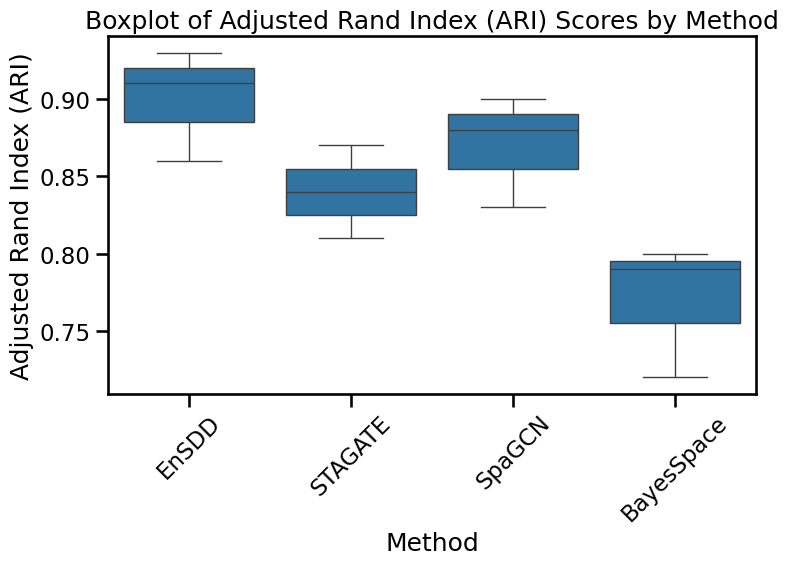

In [6]:
metric_path = "/nfs/home/students/s.reif/SysMed/SysBioSDD/evaluation_metrics/plots/"
plot_metric_boxplots(ARI_example, "Adjusted Rand Index (ARI)", metric_path)

/nfs/home/students/s.reif/.local/lib/python3.10/site-packages/plotnine/ggplot.py:615: PlotnineWarning: Saving 6.4 x 4.8 in image.
/nfs/home/students/s.reif/.local/lib/python3.10/site-packages/plotnine/ggplot.py:616: PlotnineWarning: Filename: /nfs/home/students/s.reif/SysMed/SysBioSDD/evaluation_metrics/plots/Adjusted Rand Index (ARI)_boxplot_gg.png


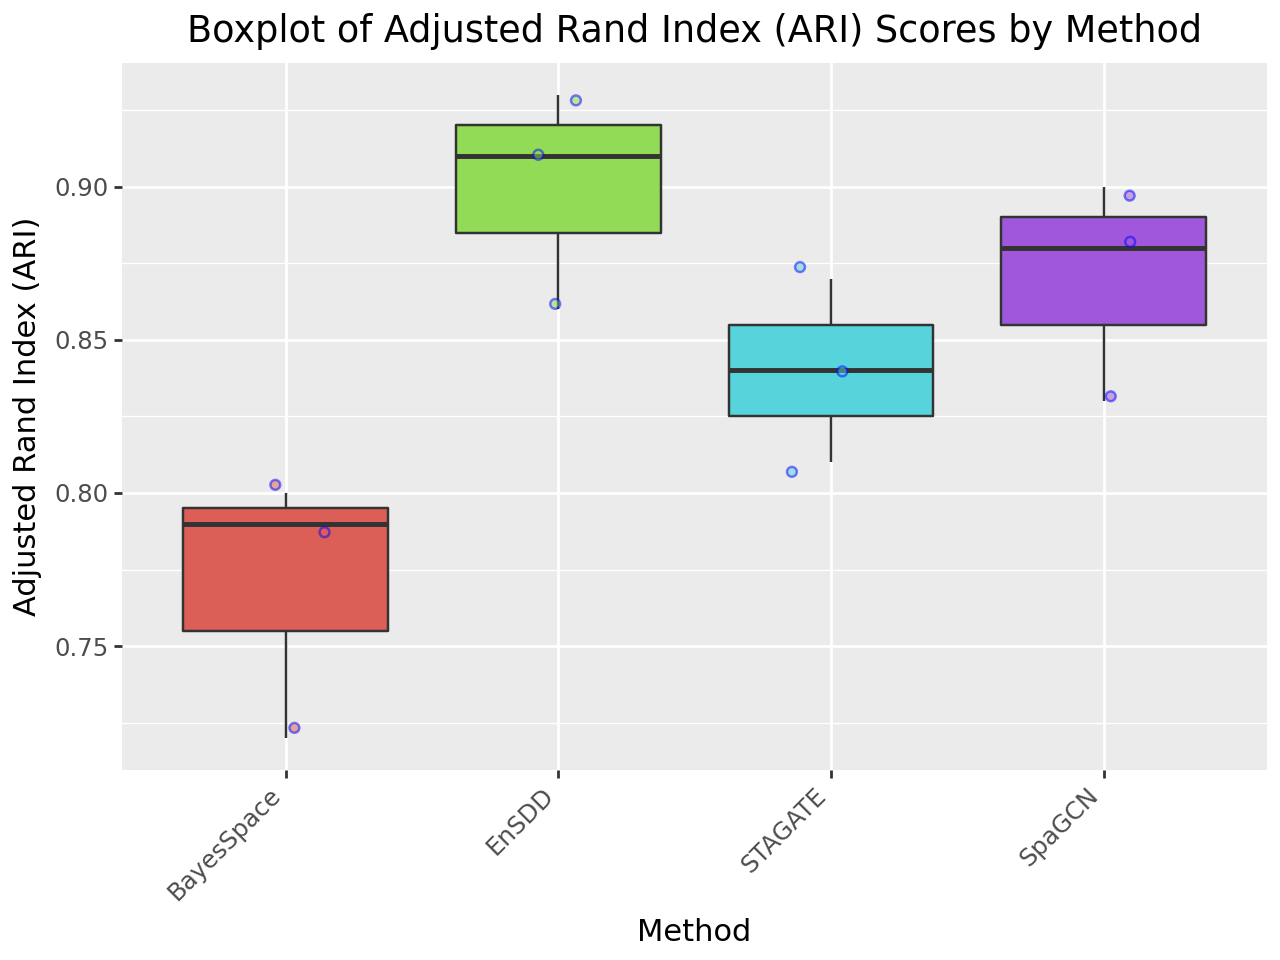

In [24]:
plot_metric_boxplots_gg(ARI_example, "Adjusted Rand Index (ARI)", metric_path)

In [25]:
# make a line plot over the datasets for each method as line and one metric
def plot_metric_lineplot_per_dataset(metric_dict, metric_name, save_path):
    # Convert to DataFrame for plotting
    data = []
    for dataset, methods in metric_dict.items():
        for method, score in methods.items():
            data.append({'Dataset': dataset, 'Method': method, 'Score': score})
    
    df = pd.DataFrame(data)
    
    # Create line plot using ggplot2
    p = (ggplot(df, aes(x='Dataset', y='Score', color='Method', group='Method')) +
         geom_line(size=1) +
         geom_point(size=2) +
         ggtitle(f'Line Plot of {metric_name} Scores by Method across Datasets') +
         xlab('Dataset') +
         ylab(metric_name) +
         theme(axis_text_x=element_text(rotation=45, hjust=1)))
    p.show()
    p.save(os.path.join(save_path, f'{metric_name}_lineplot_dataset_gg.png'))

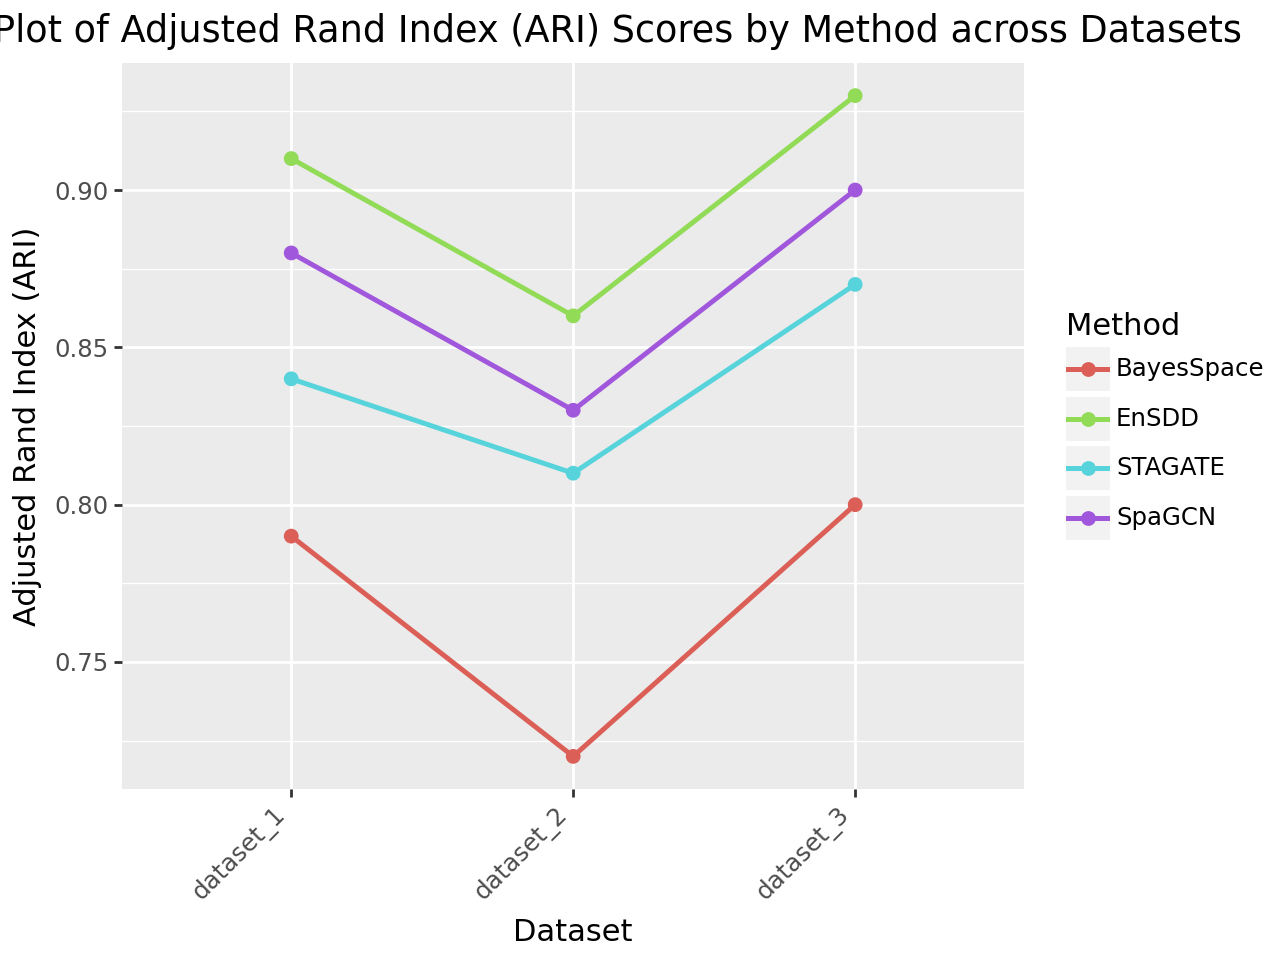

/nfs/home/students/s.reif/.local/lib/python3.10/site-packages/plotnine/ggplot.py:615: PlotnineWarning: Saving 6.4 x 4.8 in image.
/nfs/home/students/s.reif/.local/lib/python3.10/site-packages/plotnine/ggplot.py:616: PlotnineWarning: Filename: /nfs/home/students/s.reif/SysMed/SysBioSDD/evaluation_metrics/plots/Adjusted Rand Index (ARI)_lineplot_dataset_gg.png


In [26]:
plot_metric_lineplot_per_dataset(ARI_example, "Adjusted Rand Index (ARI)", metric_path)

In [28]:
metric_dicts = {
    "ARI": ARI_example,
    "Purity": Purity_example,
    "AMI": AMI_example,
    "iLISI": ILISI_example,
    "PAS": PAS_example,
    "Silhouette_expr": Silhouette_expression_example,
    "Silhouette_spatial": Silhouette_spatial_example,
}

# All datasets you processed
datasets = sorted(set().union(*[set(d.keys()) for d in metric_dicts.values()]))

data = []
for dataset in datasets:
    # union of methods across all metrics for this dataset
    methods = set()
    for md in metric_dicts.values():
        methods |= set(md.get(dataset, {}).keys())
    methods = sorted(methods)

    for method in methods:
        row = {"Dataset": dataset, "Method": method}

        # fill every metric column (NaN if missing)
        for metric_name, md in metric_dicts.items():
            row[metric_name] = md.get(dataset, {}).get(method, np.nan)

        data.append(row)

df_metrics = pd.DataFrame(data).sort_values(["Dataset", "Method"]).reset_index(drop=True)

In [29]:
df_metrics

,Dataset,Method,ARI,Purity,AMI,iLISI,PAS,Silhouette_expr,Silhouette_spatial
0,dataset_1,BayesSpace,0.79,0.86,0.74,0.52,0.14,0.31,0.41
1,dataset_1,EnSDD,0.91,0.94,0.88,0.31,0.07,0.42,0.51
2,dataset_1,STAGATE,0.84,0.89,0.79,0.44,0.11,0.36,0.46
3,dataset_1,SpaGCN,0.88,0.91,0.83,0.38,0.09,0.39,0.49
4,dataset_2,BayesSpace,0.72,0.82,0.68,0.55,0.16,0.28,0.39
5,dataset_2,EnSDD,0.86,0.90,0.82,0.36,0.08,0.38,0.47
6,dataset_2,STAGATE,0.81,0.86,0.76,0.47,0.13,0.33,0.43
7,dataset_2,SpaGCN,0.83,0.88,0.79,0.41,0.10,0.35,0.45
8,dataset_3,BayesSpace,0.80,0.87,0.75,0.50,0.13,0.32,0.42
9,dataset_3,EnSDD,0.93,0.95,0.90,0.28,0.06,0.45,0.53


In [31]:
metric_cols = list(metric_dicts.keys())  # ["ARI","Purity",...]
mean_df_metrics = (
    df_metrics
    .groupby("Method", as_index=False)[metric_cols]
    .mean(numeric_only=True)
)

mean_df_metrics


,Method,ARI,Purity,AMI,iLISI,PAS,Silhouette_expr,Silhouette_spatial
0,BayesSpace,0.77,0.850000,0.723333,0.523333,0.143333,0.303333,0.406667
1,EnSDD,0.90,0.930000,0.866667,0.316667,0.070000,0.416667,0.503333
2,STAGATE,0.84,0.883333,0.786667,0.436667,0.113333,0.353333,0.456667
3,SpaGCN,0.87,0.903333,0.823333,0.380000,0.090000,0.383333,0.480000


In [36]:
def plot_means_gg(mean_df, save_path):
    # long format: Method | Metric | Mean_Score
    df_long = mean_df.melt(id_vars=["Method"], var_name="Metric", value_name="Mean_Score")

    p = (
        ggplot(df_long, aes(x="Method", y="Mean_Score", color="Metric", group="Metric"))
        + geom_line(size=1)
        + geom_point(size=2)
        + ggtitle("Mean Metric Scores by Method")
        + xlab("Method")
        + ylab("Mean score")
        + theme(axis_text_x=element_text(rotation=45, hjust=1))
    )

    # show + save
    print(p)
    p.save(os.path.join(save_path, "mean_metrics_lineplot_gg.png"), dpi=300)

    return p

<ggplot: (640 x 480)>


/nfs/home/students/s.reif/.local/lib/python3.10/site-packages/plotnine/ggplot.py:615: PlotnineWarning: Saving 6.4 x 4.8 in image.
/nfs/home/students/s.reif/.local/lib/python3.10/site-packages/plotnine/ggplot.py:616: PlotnineWarning: Filename: /nfs/home/students/s.reif/SysMed/SysBioSDD/evaluation_metrics/plots/mean_metrics_lineplot_gg.png


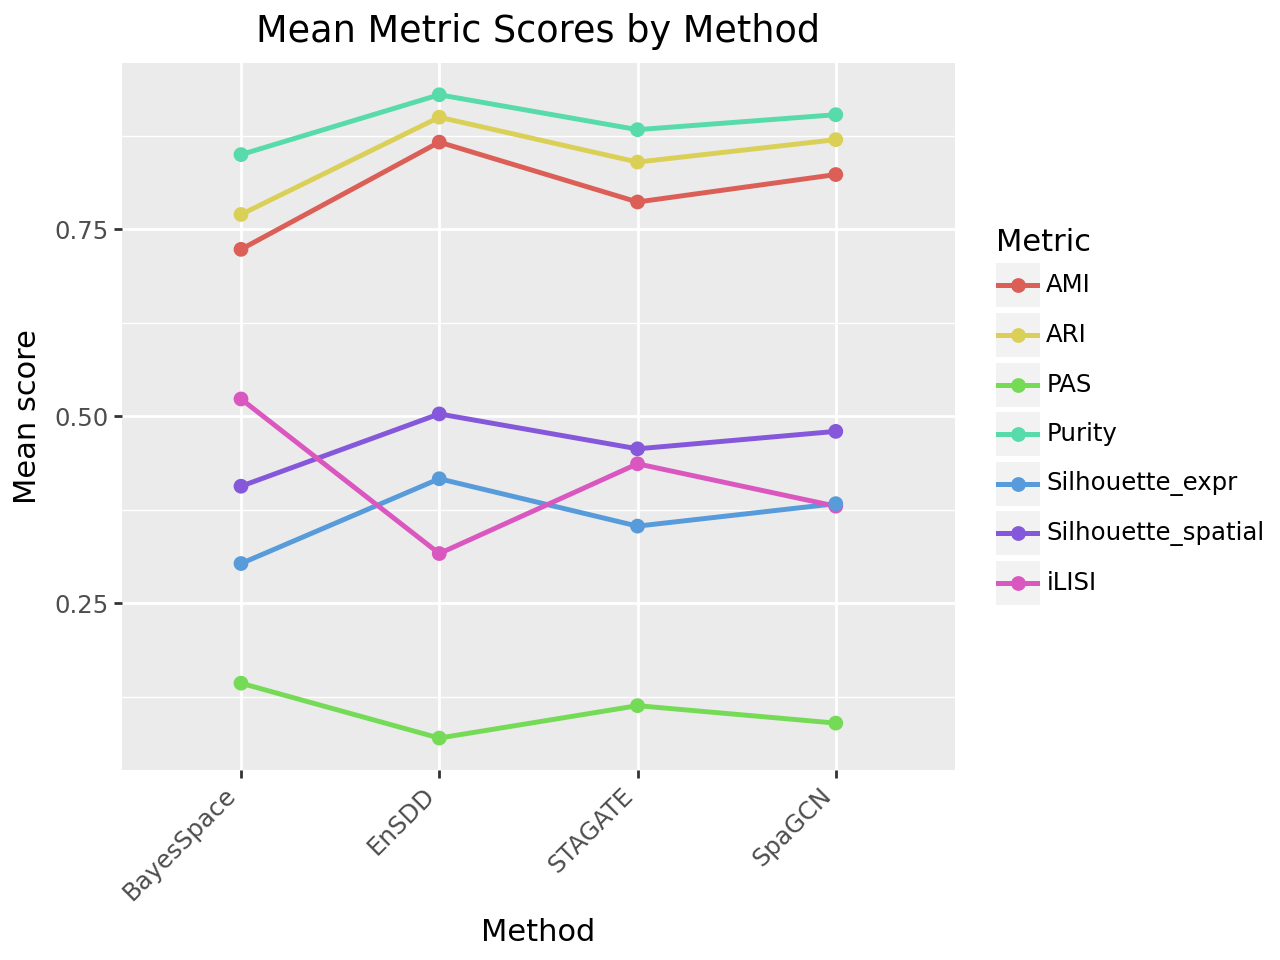

In [37]:
plot_means_gg(mean_df_metrics, metric_path)

### read in and separate examples

In [7]:
adata_graphst = sc.read_h5ad("/nfs/home/students/s.reif/SysMed/SysBioSDD/evaluation_metrics/examples/real_size_examples/graphst_visium_mouse_brain_coronal.h5ad")
adata_graphst

AnnData object with n_obs × n_vars = 704 × 16562
    obs: 'in_tissue', 'array_row', 'array_col', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_MT', 'log1p_total_counts_MT', 'pct_counts_MT', 'n_counts', 'leiden', 'cluster', 'features_summary_cluster', 'features_histogram_cluster', 'features_texture_cluster', 'mclust', 'domain'
    var: 'gene_ids', 'feature_types', 'genome', 'MT', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'cluster_co_occurrence', 'cluster_colors', 'cluster_ligrec', 'cluster_nhood_enrichment', 'domain_colors', 'hvg', 'leiden', 'leiden_colors', 'moranI', 'neighbors', 'pca', 'spatial', 'spatial_neighbors', 'umap'
    obsm: 

In [3]:
adata_graphst.obs

,in_tissue,array_row,array_col,n_genes_by_counts,log1p_n_genes_by_counts,total_counts,log1p_total_counts,pct_counts_in_top_50_genes,pct_counts_in_top_100_genes,pct_counts_in_top_200_genes,...,log1p_total_counts_MT,pct_counts_MT,n_counts,leiden,cluster,features_summary_cluster,features_histogram_cluster,features_texture_cluster,mclust,domain
AAACGAGACGGTTGAT-1,1,35,79,3808,8.245122,9285.0,9.136263,23.155627,28.723748,36.241249,...,0.0,0.0,9285.0,3,Thalamus_1,5,6,8,1,1
AAAGGGATGTAGCAAG-1,1,24,62,5288,8.573384,16644.0,9.719865,19.718818,25.666907,33.699832,...,0.0,0.0,16644.0,2,Hippocampus,9,5,0,2,2
AAATGGCATGTCTTGT-1,1,13,69,5191,8.554874,15977.0,9.678968,20.629655,26.757213,34.743694,...,0.0,0.0,15977.0,0,Cortex_1,0,0,4,3,3
AAATGGTCAATGTGCC-1,1,33,51,4923,8.501876,12454.0,9.429877,21.711900,26.818693,33.948932,...,0.0,0.0,12454.0,13,Lateral_ventricle,8,6,2,4,4
AAATTAACGGGTAGCT-1,1,34,58,4045,8.305484,11166.0,9.320718,27.261329,33.100484,40.847215,...,0.0,0.0,11166.0,2,Hippocampus,9,5,8,12,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TTGTCGTTCAGTTACC-1,1,22,58,3443,8.144389,8103.0,9.000113,22.695298,29.877823,38.837468,...,0.0,0.0,8103.0,4,Fiber_tracts,4,12,9,5,3
TTGTGGCCCTGACAGT-1,1,18,60,4971,8.511577,14779.0,9.601030,21.381690,27.924758,36.213546,...,0.0,0.0,14779.0,0,Cortex_1,1,1,6,3,3
TTGTTAGCAAATTCGA-1,1,22,42,4820,8.480737,14396.0,9.574775,20.595999,26.674076,34.655460,...,0.0,0.0,14396.0,5,Cortex_3,2,1,5,10,10
TTGTTCAGTGTGCTAC-1,1,24,64,3372,8.123558,8671.0,9.067855,28.578019,34.794141,42.647907,...,0.0,0.0,8671.0,2,Hippocampus,3,8,0,2,2


In [9]:
adata_graphst.obs['domain'].to_csv("/nfs/home/students/s.reif/SysMed/SysBioSDD/evaluation_metrics/examples/real_size_examples/graphst_visium_mouse_brain_coronal_domain.csv", index=False, header=False)